# Improved RamanNet Retraining Workflow

This notebook is aimed to improve the model developed in ramannet_crossv and achieve a higher accuarcy result in classification of bacterial spectra.

The most important rule: a saved .keras model file is trusted only if the reloaded model gives the same test accuracy as the in-memory model.

## 1. Imports and Reproducibility

Run this first. The notebook assumes it is opened either from the repository root or from the `Bacteria` folder.

In [1]:
from datetime import datetime
from pathlib import Path
import shutil

import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import BackupAndRestore, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.layers import (
    Activation,
    Add,
    BatchNormalization,
    Conv1D,
    Dense,
    Dropout,
    Flatten,
    Input,
    MaxPooling1D,
    SpatialDropout1D,
)
from tensorflow.keras.models import Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import ramanspy as rp

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

## 2. Paths and Run Folder

Each retraining attempt gets its own timestamped folder under `Bacteria/runs/`. All checkpoints, figures, final models, and verification outputs for that attempt stay together.

In [2]:
def find_bacteria_dir():
    candidates = [Path.cwd(), Path.cwd() / "Bacteria"]
    for candidate in candidates:
        if (candidate / "data" / "X_reference.npy").exists():
            return candidate
    raise FileNotFoundError("Could not find Bacteria/data/X_reference.npy")


BACTERIA_DIR = find_bacteria_dir()
DATA_DIR = BACTERIA_DIR / "data"
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_light_head")
RUN_DIR = BACTERIA_DIR / "runs" / RUN_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
FIGURE_DIR = RUN_DIR / "figures"
MODEL_DIR = RUN_DIR / "models"

for directory in [RUN_DIR, CHECKPOINT_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Bacteria directory: {BACTERIA_DIR}")
print(f"Data directory:     {DATA_DIR}")
print(f"Run directory:      {RUN_DIR}")

Bacteria directory: C:\Users\Rima\Documents\phd work\Raman\Bacteria
Data directory:     C:\Users\Rima\Documents\phd work\Raman\Bacteria\data
Run directory:      C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head


## 3. Load the Official Dataset Split

The bacteria dataset has a domain-adaptation structure:

- `train/reference`: 60,000 spectra for pretraining;
- `val/finetune`: 3,000 spectra for target-domain adaptation;
- `test`: 3,000 held-out spectra for the final result.

The arrays are already scaled to `[0, 1]`, so no extra min-max normalization is applied.

In [3]:
X_ref_sc, y_ref = rp.datasets.bacteria("train", folder=DATA_DIR)
X_ft_sc, y_ft = rp.datasets.bacteria("val", folder=DATA_DIR)
X_test_sc, y_test = rp.datasets.bacteria("test", folder=DATA_DIR)
y_labels, antibiotics_labels = rp.datasets.bacteria("labels")

X_ref = X_ref_sc.spectral_data.astype("float32")
X_ft = X_ft_sc.spectral_data.astype("float32")
X_test = X_test_sc.spectral_data.astype("float32")

X_ref_cnn = X_ref[..., np.newaxis]
X_ft_cnn = X_ft[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

num_classes = len(y_labels)
input_dim = X_ref.shape[1]

y_ref_cat = tf.keras.utils.to_categorical(y_ref, num_classes)
y_ft_cat = tf.keras.utils.to_categorical(y_ft, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

print("Reference:", X_ref_cnn.shape, y_ref_cat.shape)
print("Fine-tune:", X_ft_cnn.shape, y_ft_cat.shape)
print("Test:     ", X_test_cnn.shape, y_test_cat.shape)
print("Classes:  ", num_classes)
print("Range:    ", float(X_ref.min()), float(X_ref.max()))

Reference: (60000, 1000, 1) (60000, 30)
Fine-tune: (3000, 1000, 1) (3000, 30)
Test:      (3000, 1000, 1) (3000, 30)
Classes:   30
Range:     0.0 1.0


## 4. Create a Small Pretrain Validation Probe

This validation split is used only to monitor pretraining. It is not used for the final test score. The final adaptation stage will still train on all 3,000 fine-tune spectra.

In [4]:
X_ft_train_probe, X_ft_val_probe, y_ft_train_probe, y_ft_val_probe = train_test_split(
    X_ft_cnn,
    y_ft_cat,
    test_size=0.2,
    random_state=SEED,
    stratify=y_ft,
)

print("Pretrain validation probe:", X_ft_val_probe.shape, y_ft_val_probe.shape)

Pretrain validation probe: (600, 1000, 1) (600, 30)


## 5. Define the Light-Head Location-Preserving Model

Raman peak position matters, so this model keeps coarse location information with `Flatten`. The classifier head is deliberately light to reduce overfitting on the 3,000 fine-tune spectra.

In [5]:
def residual_block(x, filters, kernel_size=5, pool=False, dropout_rate=0.0, name="res"):
    shortcut = x

    x = BatchNormalization(name=f"{name}_bn1")(x)
    x = Activation("relu", name=f"{name}_relu1")(x)
    x = Conv1D(
        filters,
        kernel_size,
        padding="same",
        kernel_initializer=HeNormal(seed=SEED),
        name=f"{name}_conv1",
    )(x)

    x = BatchNormalization(name=f"{name}_bn2")(x)
    x = Activation("relu", name=f"{name}_relu2")(x)
    x = Conv1D(
        filters,
        kernel_size,
        padding="same",
        kernel_initializer=HeNormal(seed=SEED),
        name=f"{name}_conv2",
    )(x)

    if shortcut.shape[-1] != filters:
        shortcut = Conv1D(filters, 1, padding="same", name=f"{name}_projection")(shortcut)

    x = Add(name=f"{name}_add")([x, shortcut])

    if pool:
        x = MaxPooling1D(pool_size=2, name=f"{name}_pool")(x)

    if dropout_rate:
        x = SpatialDropout1D(dropout_rate, name=f"{name}_spatial_dropout")(x)

    return x


def create_light_head_ramannet(input_dim=1000, num_classes=30):
    inputs = Input(shape=(input_dim, 1), name="spectrum")

    x = Conv1D(
        16,
        kernel_size=9,
        padding="same",
        kernel_initializer=HeNormal(seed=SEED),
        name="stem_conv",
    )(inputs)
    x = BatchNormalization(name="stem_bn")(x)
    x = Activation("relu", name="stem_relu")(x)

    x = residual_block(x, 16, kernel_size=5, pool=False, dropout_rate=0.05, name="block1")
    x = residual_block(x, 32, kernel_size=5, pool=True, dropout_rate=0.08, name="block2")
    x = residual_block(x, 64, kernel_size=3, pool=True, dropout_rate=0.10, name="block3")
    x = residual_block(x, 64, kernel_size=3, pool=False, dropout_rate=0.10, name="block4")

    x = Flatten(name="location_preserving_flatten")(x)
    x = Dense(96, activation="relu", kernel_initializer=HeNormal(seed=SEED), name="dense_96_light")(x)
    x = Dropout(0.35, name="classifier_dropout")(x)
    outputs = Dense(num_classes, activation="softmax", name="species_softmax")(x)

    return Model(inputs, outputs, name="LightHeadRamanNet")


model = create_light_head_ramannet(input_dim=input_dim, num_classes=num_classes)
model.summary()

Model: "LightHeadRamanNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ spectrum (InputLayer)         │ (None, 1000, 1)           │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv (Conv1D)            │ (None, 1000, 16)          │             160 │ spectrum[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)  │ (None, 1000, 16)          │              64 │ stem_conv[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_relu (Activation)        │ (None, 1000, 16)          │               0 │ stem_bn[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_bn1                    │ (None, 1000, 16)          │              64 │ stem_relu[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_relu1 (Activation)     │ (None, 1000, 16)          │               0 │ block1_bn1[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_conv1 (Conv1D)         │ (None, 1000, 16)          │           1,296 │ block1_relu1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_bn2                    │ (None, 1000, 16)          │              64 │ block1_conv1[0][0]         │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_relu2 (Activation)     │ (None, 1000, 16)          │               0 │ block1_bn2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_conv2 (Conv1D)         │ (None, 1000, 16)          │           1,296 │ block1_relu2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_add (Add)              │ (None, 1000, 16)          │               0 │ block1_conv2[0][0],        │
│                               │                           │                 │ stem_relu[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1_spatial_dropout        │ (None, 1000, 16)          │               0 │ block1_add[0][0]           │
│ (SpatialDropout1D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block2_bn1                    │ (None, 1000, 16)          │              64 │ block1_spatial_dropout[0]… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block2_relu1 (Activation)     │ (None, 1000, 16)          │               0 │ block2_bn1[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block2_conv1 (Conv1D)         │ (None, 1000, 32)          │           2,59

 Total params: 1,596,702 (6.09 MB)

 Trainable params: 1,596,062 (6.09 MB)

 Non-trainable params: 640 (2.50 KB)

## 6. Optimizer Helper

Uses AdamW when available. If your TensorFlow version does not include AdamW, it falls back to Adam.

In [6]:
def make_adamw(learning_rate, weight_decay=1e-4):
    try:
        return tf.keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay)
    except AttributeError:
        return tf.keras.optimizers.Adam(learning_rate=learning_rate)

## 7. Pretrain on Reference Spectra

This stage learns broad bacterial Raman features from the 60,000 reference spectra. The best pretrain weights are saved inside the run folder and restored automatically.

In [7]:
pretrain_weights_path = CHECKPOINT_DIR / "pretrain_best.weights.h5"

model.compile(
    optimizer=make_adamw(learning_rate=1e-3, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.03),
    metrics=["accuracy"],
)

pretrain_callbacks = [
    ModelCheckpoint(
        filepath=str(pretrain_weights_path),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    BackupAndRestore(backup_dir=str(CHECKPOINT_DIR / "pretrain_backup")),
]

pretrain_history = model.fit(
    X_ref_cnn,
    y_ref_cat,
    epochs=50,
    batch_size=128,
    validation_data=(X_ft_val_probe, y_ft_val_probe),
    callbacks=pretrain_callbacks,
    verbose=1,
)

print(f"Best pretrain weights: {pretrain_weights_path}")

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.2097 - loss: 3.0698
Epoch 1: val_accuracy improved from -inf to 0.27167, saving model to C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\checkpoints\pretrain_best.weights.h5
469/469 ━━━━━━━━━━━━━━━━━━━━ 190s 389ms/step - accuracy: 0.2099 - loss: 3.0686 - val_accuracy: 0.2717 - val_loss: 3.1980 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.4819 - loss: 1.7427
Epoch 2: val_accuracy did not improve from 0.27167
469/469 ━━━━━━━━━━━━━━━━━━━━ 167s 356ms/step - accuracy: 0.4820 - loss: 1.7424 - val_accuracy: 0.2717 - val_loss: 3.7983 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.6370 - loss: 1.2941
Epoch 3: val_accuracy improved from 0.27167 to 0.36667, saving model to C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\checkpoints\pretrain_best.weights.h5
469/469 ━━━━━━━━━━━━

## 8. Final Fine-Tune on All Target-Domain Spectra

This is the final adaptation step. It uses all 3,000 fine-tune spectra for a fixed 42 epochs, based on the previous run where the validation curve peaked around this range.

In [8]:
FINAL_FINETUNE_EPOCHS = 42
finetune_last_weights_path = CHECKPOINT_DIR / "finetune_last.weights.h5"

model.compile(
    optimizer=make_adamw(learning_rate=1e-4, weight_decay=5e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.01),
    metrics=["accuracy"],
)

finetune_callbacks = [
    ModelCheckpoint(
        filepath=str(finetune_last_weights_path),
        save_weights_only=True,
        save_freq="epoch",
        verbose=1,
    ),
    BackupAndRestore(backup_dir=str(CHECKPOINT_DIR / "finetune_backup")),
]

final_finetune_history = model.fit(
    X_ft_cnn,
    y_ft_cat,
    epochs=FINAL_FINETUNE_EPOCHS,
    batch_size=32,
    callbacks=finetune_callbacks,
    verbose=1,
)

print(f"Last fine-tune weights: {finetune_last_weights_path}")

Epoch 1/42
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.4544 - loss: 2.4383
Epoch 1: saving model to C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\checkpoints\finetune_last.weights.h5
94/94 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.4548 - loss: 2.4334
Epoch 2/42
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5623 - loss: 1.5066
Epoch 2: saving model to C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\checkpoints\finetune_last.weights.h5
94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.5626 - loss: 1.5057
Epoch 3/42
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.6139 - loss: 1.3335
Epoch 3: saving model to C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\checkpoints\finetune_last.weights.h5
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.6140 - loss: 1.3328
Epoch 4/42
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.6712 - loss: 1.1769
Epoch 4: sa

## 9. Evaluate the In-Memory Model

This is the result from the model currently in memory, immediately after final fine-tuning.

In [9]:
test_loss, test_acc = model.evaluate(X_test_cnn, y_test_cat, batch_size=128, verbose=0)
y_pred_prob = model.predict(X_test_cnn, batch_size=128, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

print(f"In-memory test accuracy: {test_acc * 100:.2f}%")
print(f"In-memory test loss:     {test_loss:.4f}")
print(classification_report(y_test, y_pred, target_names=list(y_labels), digits=4))

In-memory test accuracy: 84.77%
In-memory test loss:     0.6228
                   precision    recall  f1-score   support

      C. albicans     1.0000    0.9700    0.9848       100
      C. glabrata     0.9709    1.0000    0.9852       100
     K. aerogenes     0.6789    0.7400    0.7081       100
        E. coli 1     0.8264    1.0000    0.9050       100
        E. coli 2     0.7213    0.4400    0.5466       100
       E. faecium     0.9804    1.0000    0.9901       100
    E. faecalis 1     0.8902    0.7300    0.8022       100
    E. faecalis 2     0.7238    0.7600    0.7415       100
       E. cloacae     0.7113    0.6900    0.7005       100
  K. pneumoniae 1     0.6016    0.7700    0.6754       100
  K. pneumoniae 2     0.9474    0.9000    0.9231       100
     P. mirabilis     0.6842    0.2600    0.3768       100
  P. aeruginosa 1     0.8509    0.9700    0.9065       100
  P. aeruginosa 2     0.9891    0.9100    0.9479       100
           MSSA 1     0.8130    1.0000    0.8969  

## 10. Save and Immediately Verify Reload

This cell is the guardrail. It saves the model and weights, reloads them, evaluates again, and only marks the run as verified if the reloaded accuracy matches the in-memory accuracy.

In [10]:
final_model_path = MODEL_DIR / "light_head_ramannet_verified_candidate.keras"
final_weights_path = MODEL_DIR / "light_head_ramannet_verified_candidate.weights.h5"

model.save(str(final_model_path))
model.save_weights(str(final_weights_path))

reloaded_model = tf.keras.models.load_model(str(final_model_path))
reload_loss, reload_acc = reloaded_model.evaluate(X_test_cnn, y_test_cat, batch_size=128, verbose=0)

print(f"Saved model:       {final_model_path}")
print(f"Saved weights:     {final_weights_path}")
print(f"In-memory accuracy: {test_acc * 100:.2f}%")
print(f"Reloaded accuracy:  {reload_acc * 100:.2f}%")

if abs(float(reload_acc) - float(test_acc)) <= 1e-4:
    verified_model_path = MODEL_DIR / f"light_head_ramannet_verified_{test_acc * 100:.2f}.keras"
    verified_weights_path = MODEL_DIR / f"light_head_ramannet_verified_{test_acc * 100:.2f}.weights.h5"
    shutil.copy2(final_model_path, verified_model_path)
    shutil.copy2(final_weights_path, verified_weights_path)
    print("VERIFIED: Reloaded model matches the in-memory result.")
    print(f"Verified model:   {verified_model_path}")
    print(f"Verified weights: {verified_weights_path}")
else:
    print("WARNING: Reloaded accuracy does not match. Do not use the saved model for figures yet.")

Saved model:       C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\models\light_head_ramannet_verified_candidate.keras
Saved weights:     C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\models\light_head_ramannet_verified_candidate.weights.h5
In-memory accuracy: 84.77%
Reloaded accuracy:  84.77%
VERIFIED: Reloaded model matches the in-memory result.
Verified model:   C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\models\light_head_ramannet_verified_84.77.keras
Verified weights: C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\models\light_head_ramannet_verified_84.77.weights.h5


## 11. Save Confusion Matrices

This uses the verified reloaded model if verification passed. If verification failed, it uses the in-memory predictions and prints a warning.

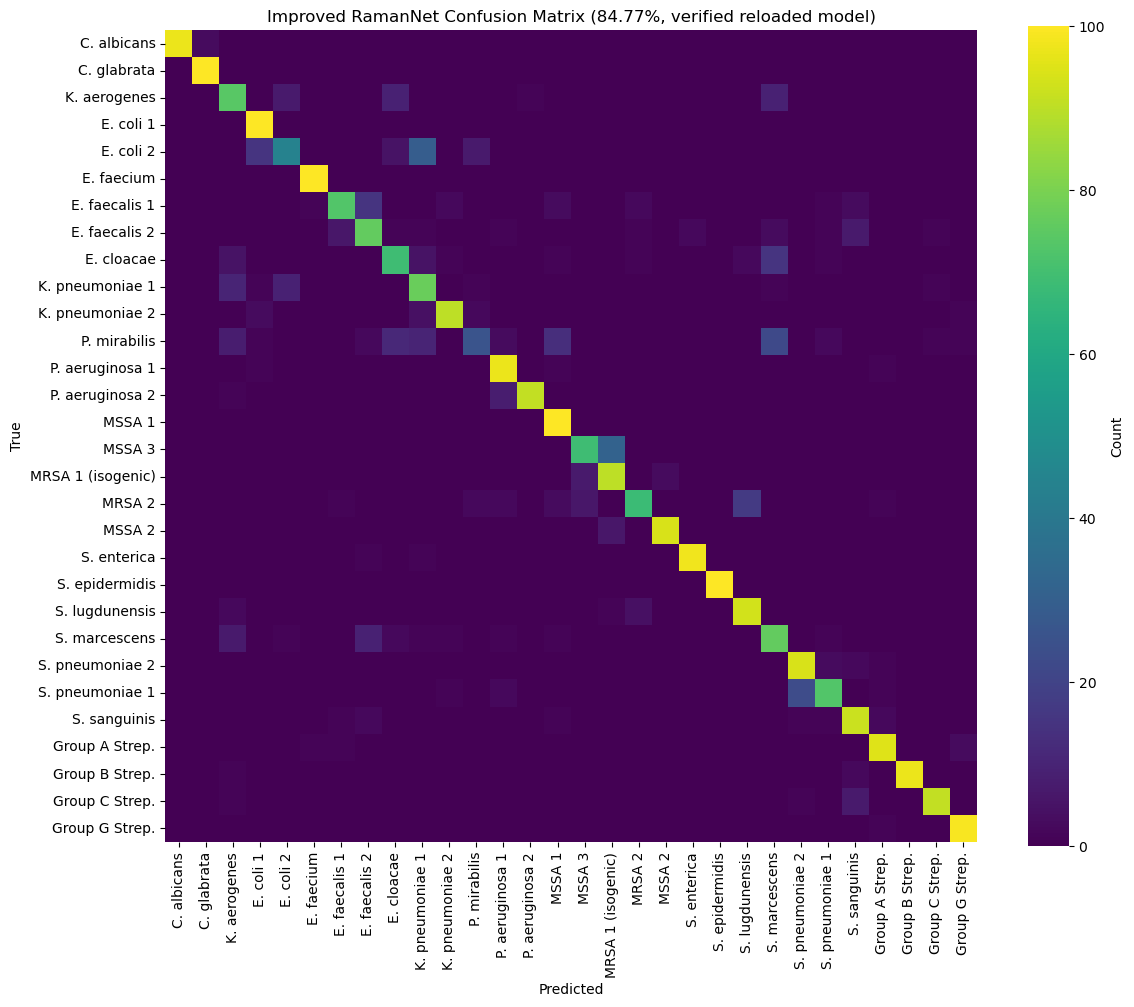

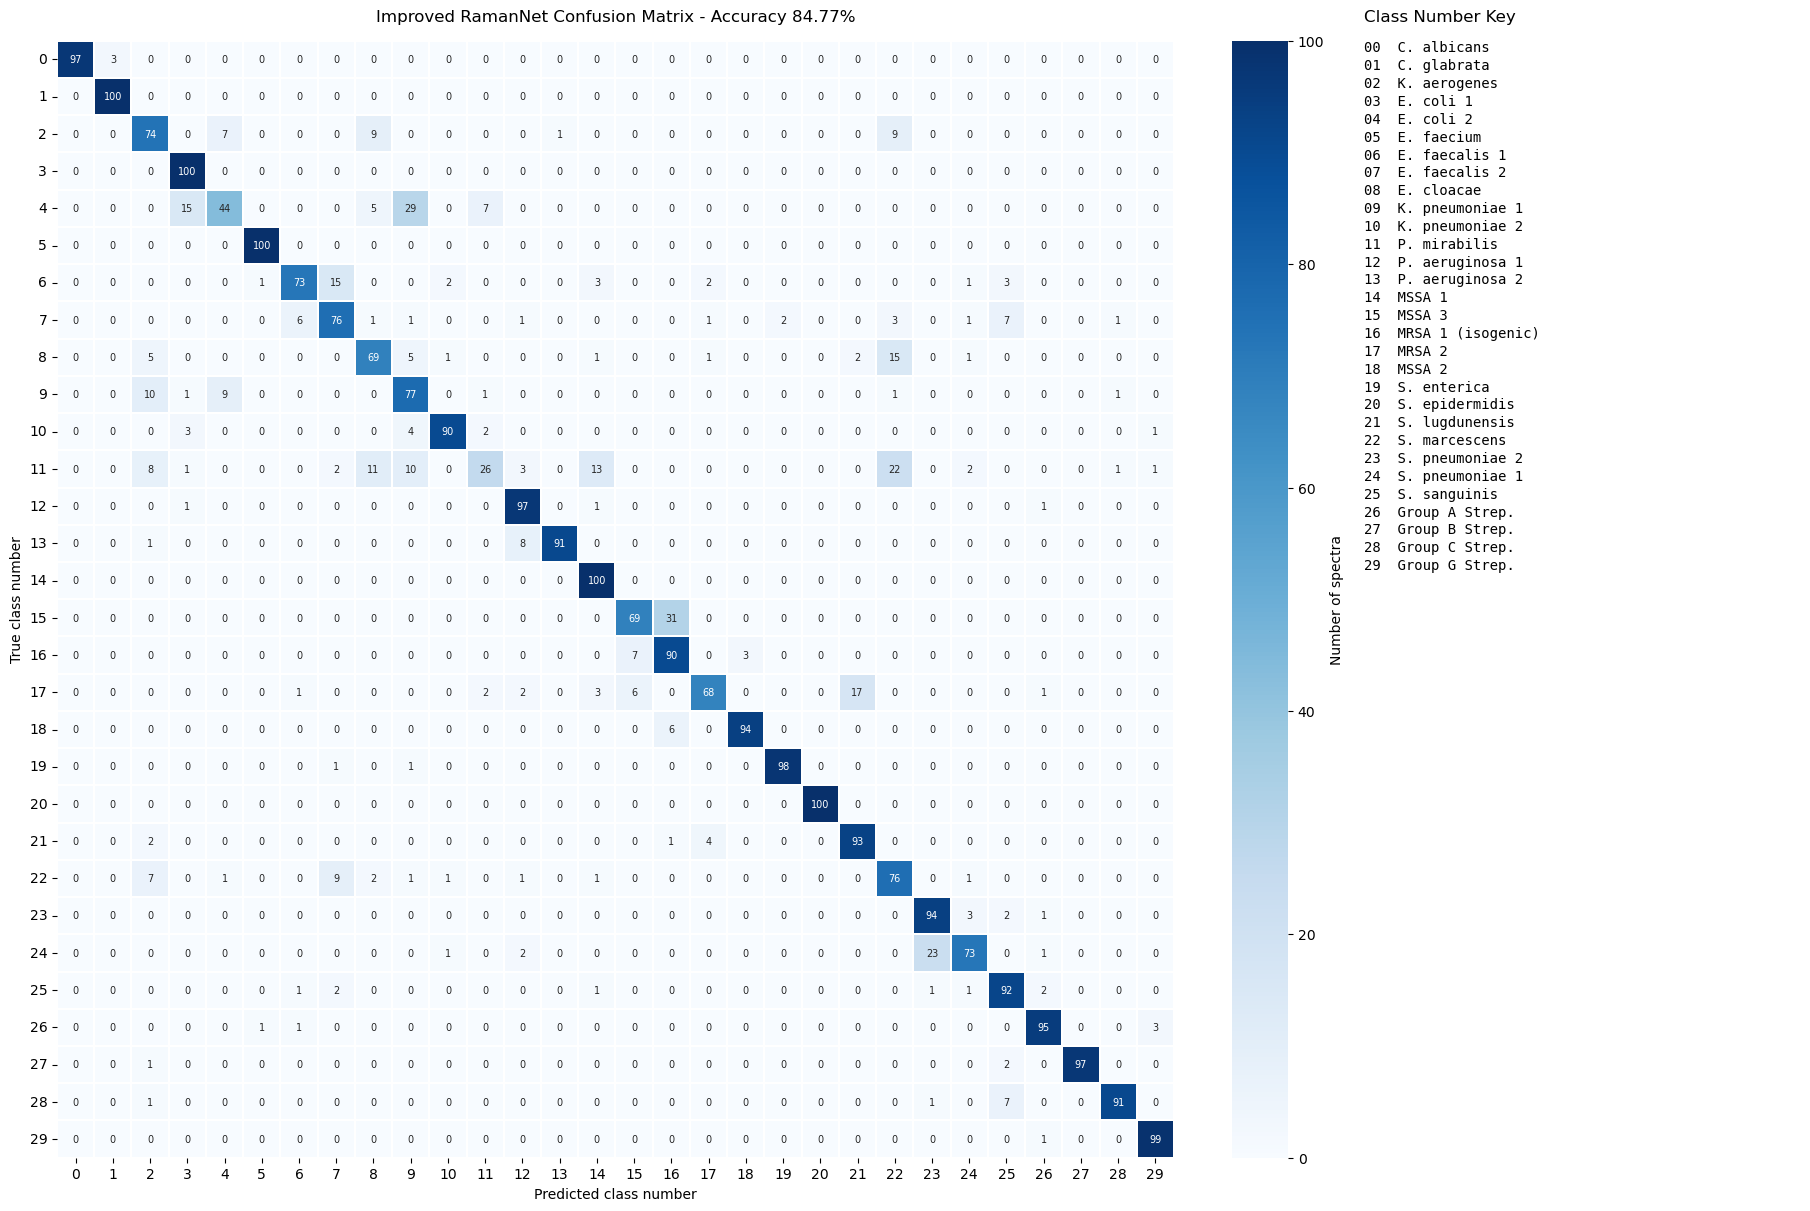

Saved labelled confusion matrix: C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\figures\confusion_matrix_labels_84.77.png
Saved numbered confusion matrix: C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\figures\confusion_matrix_numbered_84.77.png


In [11]:
if "reloaded_model" in globals() and abs(float(reload_acc) - float(test_acc)) <= 1e-4:
    plot_model = reloaded_model
    plot_pred = np.argmax(plot_model.predict(X_test_cnn, batch_size=128, verbose=0), axis=1)
    plot_acc = accuracy_score(y_test, plot_pred)
    source_label = "verified reloaded model"
else:
    plot_pred = y_pred
    plot_acc = accuracy_score(y_test, y_pred)
    source_label = "in-memory model only"
    print("WARNING: using in-memory predictions because reload verification did not pass.")

cm = confusion_matrix(y_test, plot_pred, labels=np.arange(num_classes))

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    cmap="viridis",
    xticklabels=y_labels,
    yticklabels=y_labels,
    square=True,
    cbar_kws={"label": "Count"},
)
plt.title(f"Improved RamanNet Confusion Matrix ({plot_acc * 100:.2f}%, {source_label})")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
original_label_cm_path = FIGURE_DIR / f"confusion_matrix_labels_{plot_acc * 100:.2f}.png"
plt.savefig(original_label_cm_path, dpi=300, bbox_inches="tight")
plt.show()

class_ids = np.arange(num_classes)
legend_text = "\n".join(f"{i:02d}  {name}" for i, name in enumerate(y_labels))

fig = plt.figure(figsize=(18, 12), constrained_layout=True)
grid = fig.add_gridspec(1, 2, width_ratios=[4.8, 1.8])
ax = fig.add_subplot(grid[0, 0])
sns.heatmap(
    cm,
    ax=ax,
    cmap="Blues",
    annot=True,
    fmt="d",
    annot_kws={"size": 7},
    square=True,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Number of spectra"},
)
ax.set_title(f"Improved RamanNet Confusion Matrix - Accuracy {plot_acc * 100:.2f}%", pad=14)
ax.set_xlabel("Predicted class number")
ax.set_ylabel("True class number")
ax.set_xticks(class_ids + 0.5)
ax.set_yticks(class_ids + 0.5)
ax.set_xticklabels(class_ids, rotation=0)
ax.set_yticklabels(class_ids, rotation=0)

ax_key = fig.add_subplot(grid[0, 1])
ax_key.axis("off")
ax_key.set_title("Class Number Key", loc="left", pad=14)
ax_key.text(0, 1, legend_text, va="top", ha="left", family="monospace", fontsize=10, linespacing=1.35)

numbered_cm_path = FIGURE_DIR / f"confusion_matrix_numbered_{plot_acc * 100:.2f}.png"
fig.savefig(numbered_cm_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved labelled confusion matrix: {original_label_cm_path}")
print(f"Saved numbered confusion matrix: {numbered_cm_path}")

## 12. Save Learning Curves


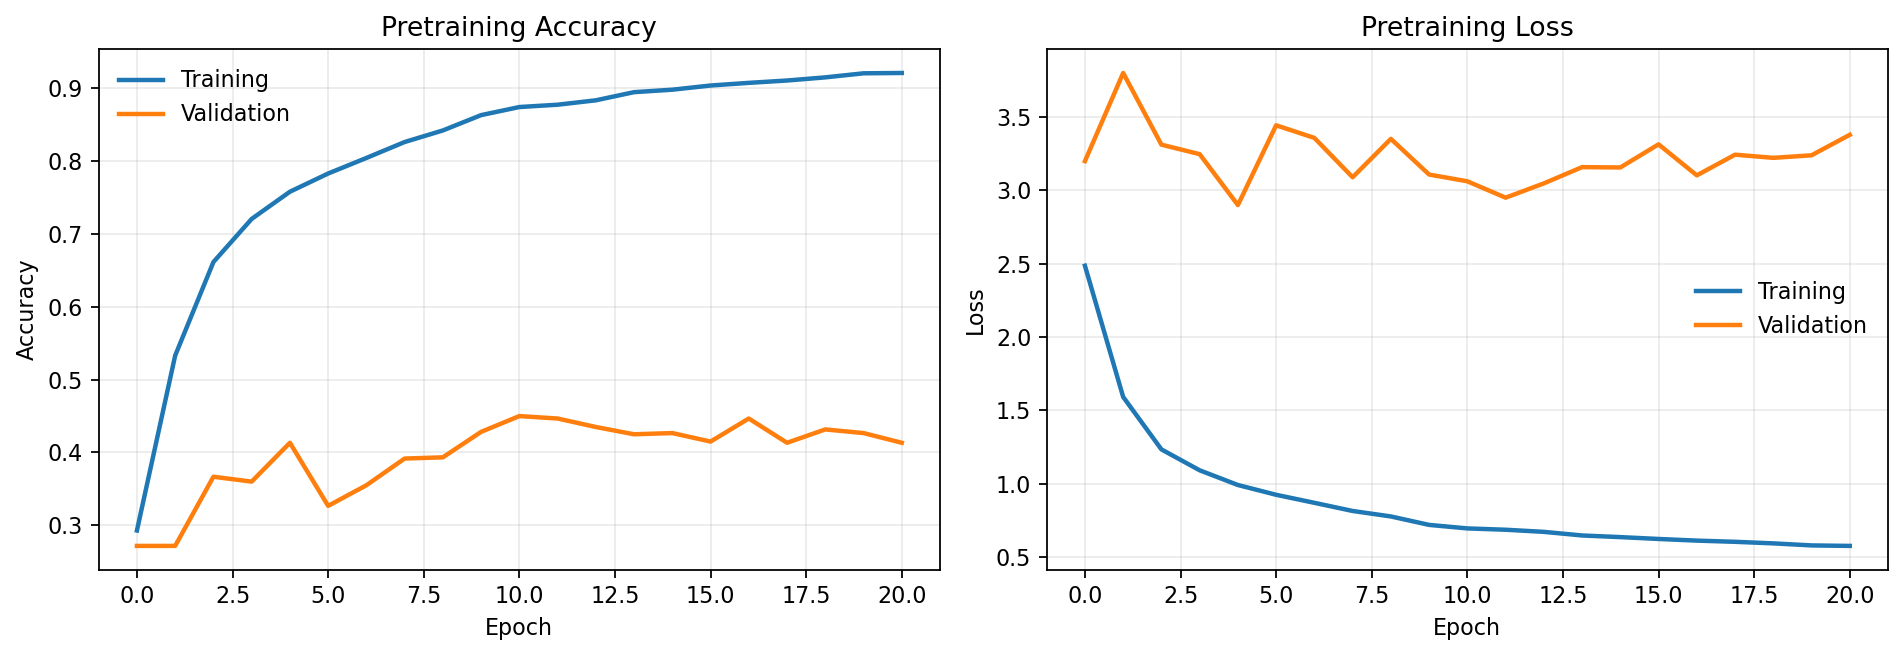

Saved: C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\figures\learning_curve_pretrain.png


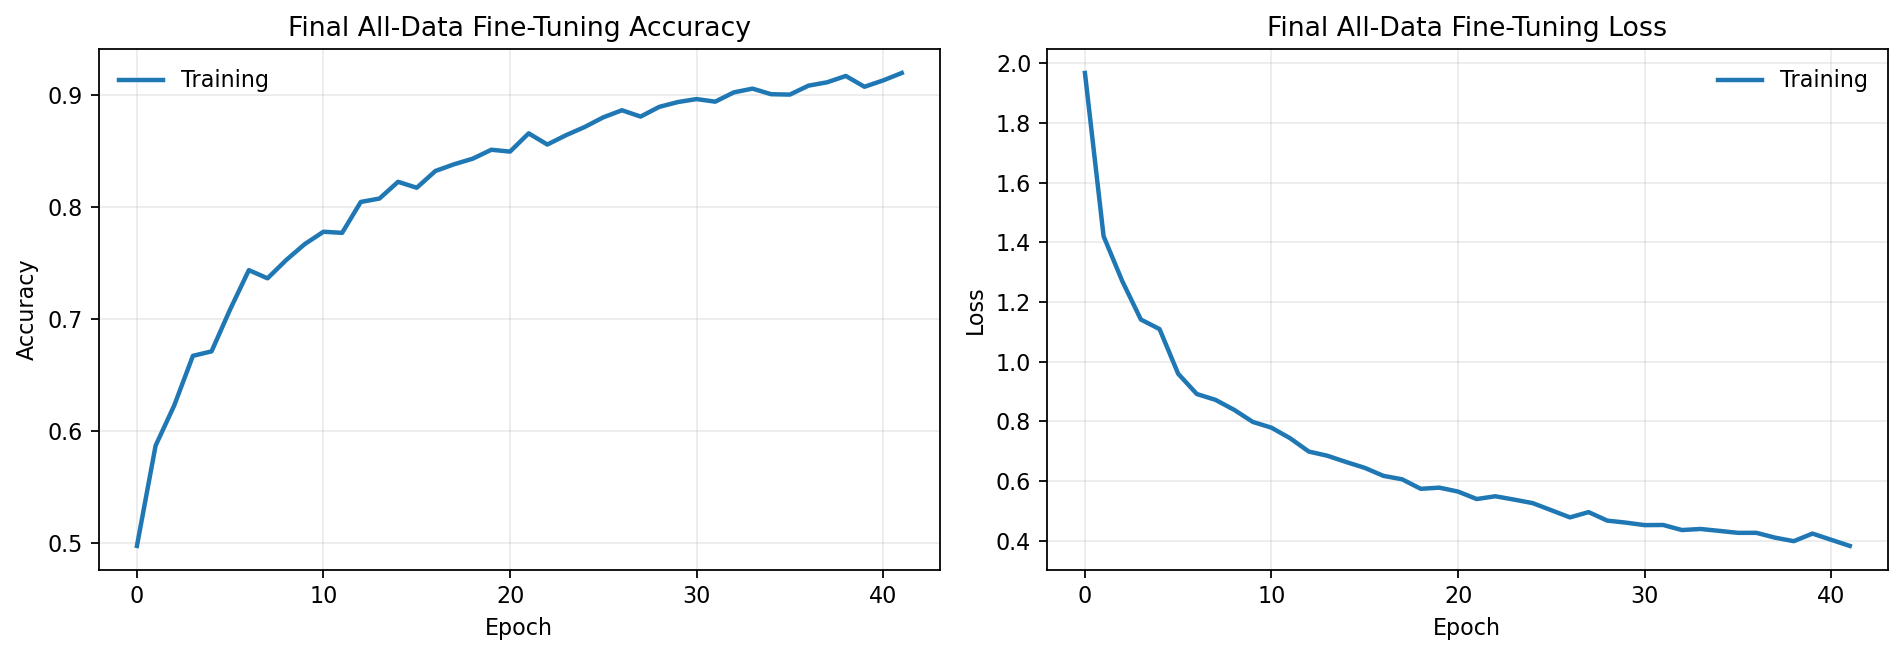

Saved: C:\Users\Rima\Documents\phd work\Raman\Bacteria\runs\20260622_132347_light_head\figures\learning_curve_final_finetune.png


In [12]:
def save_learning_curve(history, title, output_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=160)

    axes[0].plot(history.history["accuracy"], label="Training", linewidth=2)
    if "val_accuracy" in history.history:
        axes[0].plot(history.history["val_accuracy"], label="Validation", linewidth=2)
    axes[0].set_title(f"{title} Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(alpha=0.25)
    axes[0].legend(frameon=False)

    axes[1].plot(history.history["loss"], label="Training", linewidth=2)
    if "val_loss" in history.history:
        axes[1].plot(history.history["val_loss"], label="Validation", linewidth=2)
    axes[1].set_title(f"{title} Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].grid(alpha=0.25)
    axes[1].legend(frameon=False)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_path}")


save_learning_curve(pretrain_history, "Pretraining", FIGURE_DIR / "learning_curve_pretrain.png")
save_learning_curve(final_finetune_history, "Final All-Data Fine-Tuning", FIGURE_DIR / "learning_curve_final_finetune.png")

## Summery
Training accuracy reached >90%, showing strong learning of Raman features from the 60k reference spectra.
Validation was measured on 600 target-domain spectra and plateaued around 40–45%.
This gap reflects domain shift: the reference-trained model had not yet adapted to the target spectra.
Therefore, fine-tuning with the 3k fine-tune spectra was required to specialize the pretrained weights for the target dataset.

## Ideas to improve the model furhter

1. Smarter two-step classification: First, the model separates bacteria into broad groups, then smaller specialist models focus on the confusing look-alike classes. Maybe with the constrative learning approach.
2. Add synthetic Raman noise, baseline shifts, intensity changes, and cosmic-ray-like spikes during training so the model becomes more robust to real instrument variation.